<a href="https://colab.research.google.com/github/Sands225/Image-and-Video-Retrieval-Archieve/blob/main/%5BTugas_3%5D_Hilbert_Transform_dan_GLCM_Image_and_Video_Retrieval_System_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 3 - Video Retrieval berbasis Tekstur (GLCM) + Hilbert Transform


## 1. Mount Google Drive & Persiapan Environment


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q opencv-python-headless scikit-image scipy numpy pandas matplotlib

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import hilbert
from skimage.feature import graycomatrix, graycoprops

BASE_DIR = "/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3"
VIDEO_DIR = os.path.join(BASE_DIR, "dataset")

QUERY_PATHS = [
    os.path.join(BASE_DIR, "query/query_walking.png"),
    os.path.join(BASE_DIR, "query/query_running.png"),
    os.path.join(BASE_DIR, "query/query_texture.png"),
    os.path.join(BASE_DIR, "query/query_sky.png")
]

VIDEO_FILES = {
    "walking": os.path.join(VIDEO_DIR, "walking.mp4"),
    "running": os.path.join(VIDEO_DIR, "running.mp4"),
    "sitting": os.path.join(VIDEO_DIR, "sitting.mp4"),
    "sky": os.path.join(VIDEO_DIR, "sky.mp4"),
    "fabric": os.path.join(VIDEO_DIR, "fabric.mp4"),
    "wood": os.path.join(VIDEO_DIR, "wood.mp4"),
}

N_KEYFRAMES = 8
GLCM_DISTANCES = [1]
GLCM_ANGLES = [0, np.pi/4, np.pi/2, 3*np.pi/4]
RESIZE_DIM = (256, 256)

## 2. Ekstraksi Keyframe dari Video


In [ ]:
def extract_keyframes(video_path, n_keyframes=N_KEYFRAMES, resize_dim=RESIZE_DIM):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"Tidak bisa membuka video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        raise ValueError(f"Video tidak memiliki frame yang terbaca: {video_path}")

    # indeks frame yang akan diambil, tersebar merata
    idxs = np.linspace(0, total_frames - 1, num=n_keyframes, dtype=int)

    frames = []
    for idx in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame_bgr = cap.read()
        if not ret:
            continue
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        frame_rgb = cv2.resize(frame_rgb, resize_dim)
        frames.append(frame_rgb)

    cap.release()
    if len(frames) == 0:
        raise ValueError(f"Gagal mengekstrak keyframe dari: {video_path}")
    return frames

## 3. Konversi RGB -> Grayscale


In [ ]:
def rgb_to_grayscale(frame_rgb):
    """Konversi citra RGB ke grayscale (0-255, uint8) memakai bobot luminansi."""
    r = frame_rgb[:, :, 0].astype(np.float64)
    g = frame_rgb[:, :, 1].astype(np.float64)
    b = frame_rgb[:, :, 2].astype(np.float64)
    gray = 0.299 * r + 0.587 * g + 0.114 * b
    return gray.astype(np.uint8)

## 4. Fitur Tekstur GLCM (Gray Level Co-occurrence Matrix)

Untuk tiap frame grayscale dihitung GLCM pada 4 arah sudut (0°, 45°, 90°, 135°),
lalu diambil rata-rata dari 4 arah tersebut untuk setiap properti:

- **Contrast**
- **Correlation**
- **Energy**
- **Homogeneity**


In [ ]:
def compute_glcm_features(gray_img):
    glcm = graycomatrix(
        gray_img,
        distances=GLCM_DISTANCES,
        angles=GLCM_ANGLES,
        levels=256,
        symmetric=True,
        normed=True
    )

    # Mengekstrak seluruh 6 fitur GLCM lengkap
    return {
        "GLCM_Contrast": float(np.mean(graycoprops(glcm, 'contrast'))),
        "GLCM_Dissimilarity": float(np.mean(graycoprops(glcm, 'dissimilarity'))),
        "GLCM_Homogeneity": float(np.mean(graycoprops(glcm, 'homogeneity'))),
        "GLCM_Energy": float(np.mean(graycoprops(glcm, 'energy'))),
        "GLCM_Correlation": float(np.mean(graycoprops(glcm, 'correlation'))),
        "GLCM_ASM": float(np.mean(graycoprops(glcm, 'ASM'))),
    }

## 5. Fitur Tambahan: Transformasi Hilbert

Selain GLCM, digunakan **Transformasi Hilbert (Hilbert Transform)** untuk
menangkap karakteristik tekstur dari sisi domain sinyal. Setiap baris citra
grayscale diperlakukan sebagai sinyal 1D, kemudian dihitung *analytic signal*-nya
menggunakan `scipy.signal.hilbert`. Dari *envelope* (magnitude sinyal analitik)
tersebut diambil statistik ringkasan (mean, std, energi rata-rata) sebagai fitur
tambahan yang melengkapi fitur GLCM.


In [ ]:
def compute_hilbert_features(gray_img):
    """Menghitung fitur tekstur berbasis Transformasi Hilbert.

    Setiap baris citra dipandang sebagai sinyal 1D, ditransformasi dengan
    Hilbert Transform untuk mendapatkan analytic signal, lalu diambil
    envelope (magnitude)-nya. Statistik dari seluruh envelope dijadikan fitur.
    """
    gray_float = gray_img.astype(np.float64)

    # Transformasi Hilbert per baris (axis=1)
    analytic_signal = hilbert(gray_float, axis=1)
    envelope = np.abs(analytic_signal)

    # Fase sesaat (instantaneous phase)
    instantaneous_phase = np.unwrap(np.angle(analytic_signal), axis=1)
    phase_diff = np.diff(instantaneous_phase, axis=1)

    return {
        "Hilbert_Envelope_Mean": float(np.mean(envelope)),
        "Hilbert_Envelope_Std": float(np.std(envelope)),
        "Hilbert_Envelope_Energy": float(np.mean(envelope ** 2)),
        "Hilbert_PhaseDiff_Mean": float(np.mean(np.abs(phase_diff))),
    }

## 6. Membentuk Feature Vector per Frame & per Video

Untuk setiap keyframe: RGB -> Grayscale -> hitung fitur GLCM + fitur Hilbert
-> digabung jadi satu feature vector. Feature vector video = rata-rata
feature vector seluruh keyframe-nya.


In [ ]:
# Daftar fitur GLCM 4 versi awal
GLCM_4_COLS = ["GLCM_Contrast", "GLCM_Correlation", "GLCM_Energy", "GLCM_Homogeneity"]

# Daftar fitur GLCM 6 versi lengkap
GLCM_6_COLS = ["GLCM_Contrast", "GLCM_Dissimilarity", "GLCM_Homogeneity",
               "GLCM_Energy", "GLCM_Correlation", "GLCM_ASM"]

# Seluruh urutan fitur (6 GLCM + 4 Hilbert)
FEATURE_ORDER = GLCM_6_COLS + [
    "Hilbert_Envelope_Mean", "Hilbert_Envelope_Std",
    "Hilbert_Envelope_Energy", "Hilbert_PhaseDiff_Mean"
]

def extract_feature_vector_from_frame(frame_rgb):
    """Pipeline lengkap untuk satu frame: RGB -> Grayscale -> GLCM + Hilbert."""
    gray = rgb_to_grayscale(frame_rgb)
    feats = {}
    feats.update(compute_glcm_features(gray))
    feats.update(compute_hilbert_features(gray))
    return np.array([feats[k] for k in FEATURE_ORDER])


def extract_video_feature_vector(video_path, n_keyframes=N_KEYFRAMES):
    """Ekstraksi feature vector video = rata-rata feature vector seluruh keyframe."""
    frames = extract_keyframes(video_path, n_keyframes=n_keyframes)
    frame_vectors = [extract_feature_vector_from_frame(f) for f in frames]
    return np.mean(frame_vectors, axis=0), frames


## 7. Ekstraksi Fitur untuk Seluruh Video Dataset

Mengekstrak fitur dari walking (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/walking.mp4) ...
Mengekstrak fitur dari running (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/running.mp4) ...
Mengekstrak fitur dari sitting (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/sitting.mp4) ...
Mengekstrak fitur dari sky (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/sky.mp4) ...
Mengekstrak fitur dari fabric (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/fabric.mp4) ...
Mengekstrak fitur dari wood (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/wood.mp4) ...

--- Hasil Fitur GLCM ---


,GLCM_Contrast,GLCM_Dissimilarity,GLCM_Homogeneity,GLCM_Energy,GLCM_Correlation,GLCM_ASM
walking,409.084788,9.827125,0.319522,0.023849,0.887618,0.000578
running,284.382424,6.303448,0.483953,0.046958,0.939197,0.002401
sitting,279.369301,6.429742,0.375145,0.029632,0.977254,0.000893
sky,114.628688,4.780046,0.448131,0.042521,0.982042,0.001881
fabric,1567.445061,27.092998,0.059483,0.011345,0.542685,0.000167
wood,239.882126,7.885815,0.282779,0.034795,0.741777,0.001228



--- Hasil Fitur Hilbert ---


,Hilbert_Envelope_Mean,Hilbert_Envelope_Std,Hilbert_Envelope_Energy,Hilbert_PhaseDiff_Mean
walking,113.363580,41.976440,14614.941522,0.111499
running,128.421841,48.090838,18934.119492,0.034930
sitting,115.296953,78.580981,19475.361036,0.066642
sky,134.477178,56.335384,21445.826197,0.041430
fabric,117.149628,40.810579,16250.411710,0.278608
wood,86.994230,20.378849,7983.339848,0.115859


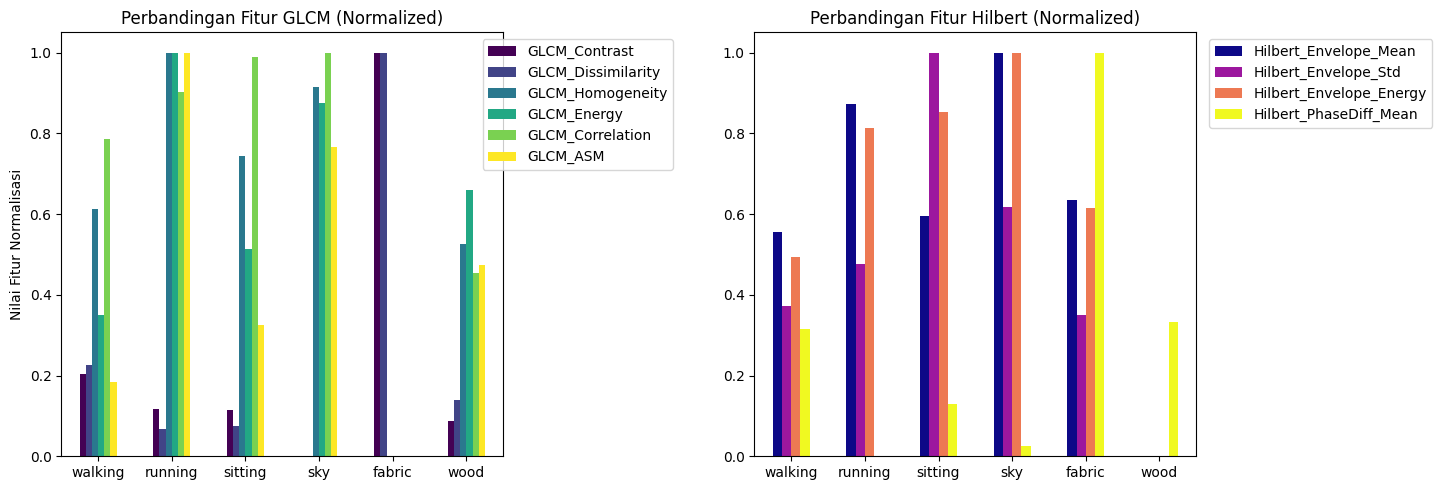

In [ ]:
video_features = {}
video_keyframes_preview = {}

for video_id, path in VIDEO_FILES.items():
    print(f"Mengekstrak fitur dari {video_id} ({path}) ...")
    vec, frames = extract_video_feature_vector(path)
    video_features[video_id] = vec
    video_keyframes_preview[video_id] = frames[0]

# Membuat DataFrame utama
df_features = pd.DataFrame(video_features, index=FEATURE_ORDER).T

# Memisahkan fitur GLCM dan Hilbert untuk perbandingan
glcm_cols = [col for col in df_features.columns if "GLCM" in col]
hilbert_cols = [col for col in df_features.columns if "Hilbert" in col]

df_glcm = df_features[glcm_cols]
df_hilbert = df_features[hilbert_cols]

print("\n--- Hasil Fitur GLCM ---")
display(df_glcm)

print("\n--- Hasil Fitur Hilbert ---")
display(df_hilbert)

# Normalisasi Min-Max agar rentang nilai (skala) fitur dapat divisualisasikan dengan seimbang
df_normalized = (df_features - df_features.min()) / (df_features.max() - df_features.min() + 1e-9)

# Visualisasi perbandingan nilai fitur per video
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df_normalized[glcm_cols].plot(kind='bar', ax=axes[0], colormap='viridis', title='Perbandingan Fitur GLCM (Normalized)')
axes[0].set_ylabel('Nilai Fitur Normalisasi')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(loc='upper right', bbox_to_anchor=(1.4, 1))

df_normalized[hilbert_cols].plot(kind='bar', ax=axes[1], colormap='plasma', title='Perbandingan Fitur Hilbert (Normalized)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(loc='upper right', bbox_to_anchor=(1.55, 1))

plt.tight_layout()
plt.show()

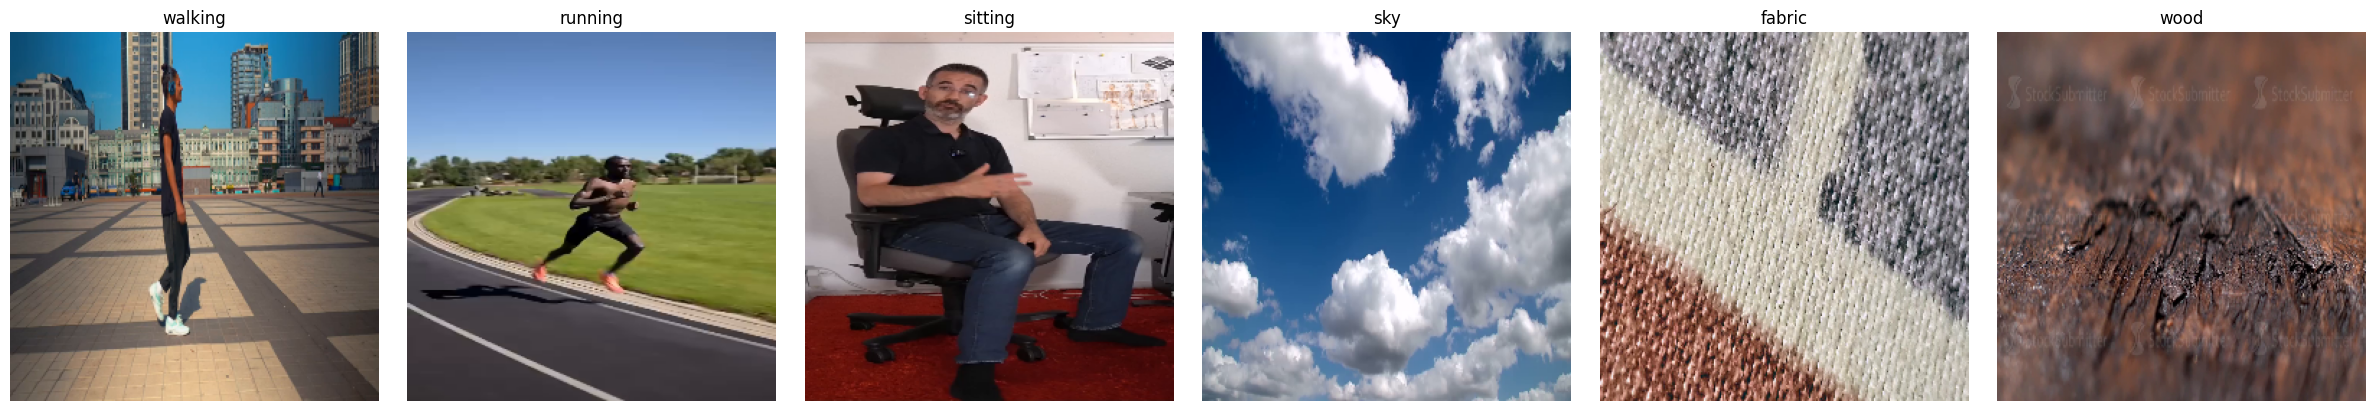

In [ ]:
# Preview 1 keyframe representatif dari tiap video
fig, axes = plt.subplots(1, len(video_keyframes_preview), figsize=(4 * len(video_keyframes_preview), 4))
for ax, (video_id, frame) in zip(axes, video_keyframes_preview.items()):
    ax.imshow(frame)
    ax.set_title(video_id)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Ekstraksi Fitur untuk Query (Gambar)


HASIL RETRIEVAL UNTUK: walking


,Rank 4-Fitur,Jarak (4 Fitur),Rank 6-Fitur,Jarak (6 Fitur)
0,sitting,0.1103,sitting,0.1418
1,sky,0.2391,sky,0.3850
2,walking,0.3168,walking,0.3984
3,running,0.3699,wood,0.4548
4,wood,0.4426,running,0.6235
5,fabric,1.2184,fabric,1.4126


HASIL RETRIEVAL UNTUK: running


,Rank 4-Fitur,Jarak (4 Fitur),Rank 6-Fitur,Jarak (6 Fitur)
0,running,0.1279,sky,0.1900
1,sky,0.1694,running,0.1958
2,sitting,0.4736,sitting,0.6601
3,wood,0.6566,wood,0.7431
4,walking,0.6656,walking,0.8958
5,fabric,1.5013,fabric,1.7945


HASIL RETRIEVAL UNTUK: texture


,Rank 4-Fitur,Jarak (4 Fitur),Rank 6-Fitur,Jarak (6 Fitur)
0,fabric,0.5373,fabric,0.6368
1,wood,1.3800,walking,1.6341
2,walking,1.4003,wood,1.6925
3,sitting,1.6023,sitting,1.8714
4,sky,1.8189,sky,2.1701
5,running,1.8308,running,2.2333


HASIL RETRIEVAL UNTUK: sky


,Rank 4-Fitur,Jarak (4 Fitur),Rank 6-Fitur,Jarak (6 Fitur)
0,running,0.2163,running,0.2472
1,sky,0.2426,sky,0.3906
2,sitting,0.5133,wood,0.7814
3,wood,0.5424,sitting,0.8554
4,walking,0.6674,walking,1.0539
5,fabric,1.4175,fabric,1.8228


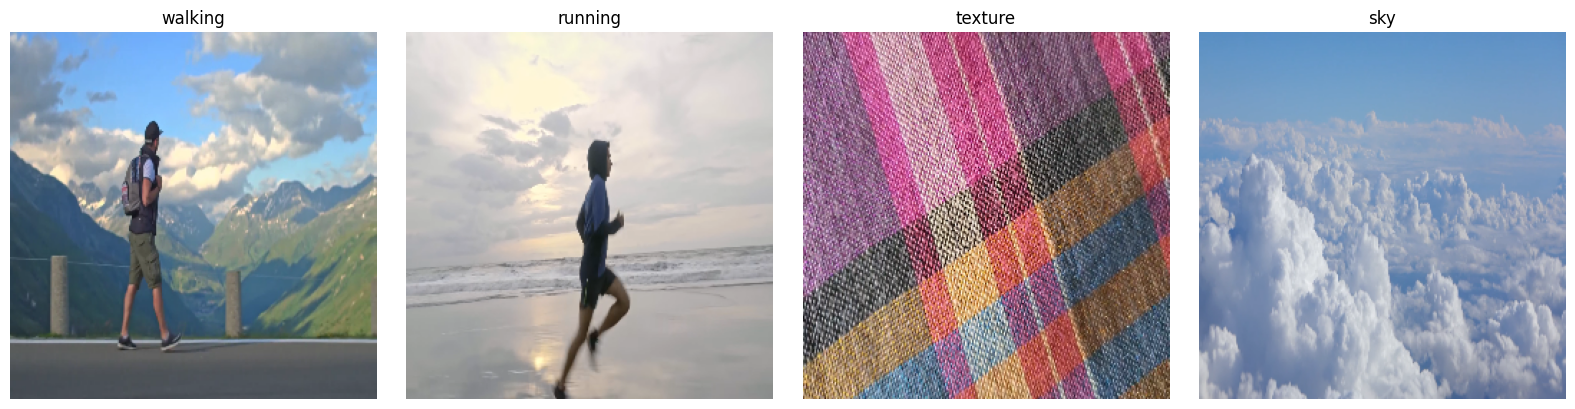


=== Tabel Vektor Fitur untuk Seluruh Query ===


,walking,running,texture,sky
GLCM_Contrast,119.710666,93.331131,2678.657416,69.889457
GLCM_Dissimilarity,4.659081,3.300013,39.305947,4.454192
GLCM_Homogeneity,0.403448,0.525315,0.029907,0.400056
GLCM_Energy,0.032785,0.045346,0.007573,0.051617
GLCM_Correlation,0.973613,0.972239,0.344914,0.930801
GLCM_ASM,0.001088,0.002079,0.000058,0.002685
Hilbert_Envelope_Mean,134.384385,191.102526,124.526400,156.960604
Hilbert_Envelope_Std,47.350115,37.360563,44.386556,22.833091
Hilbert_Envelope_Energy,20301.196395,37915.987157,17476.990579,25157.981103
Hilbert_PhaseDiff_Mean,0.038250,0.021952,0.382767,0.031169


In [ ]:
# ====================================================
# 1. Fungsi Ekstraksi Vektor Fitur Query
# ====================================================
def extract_query_feature_vector(image_path, resize_dim=RESIZE_DIM):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Tidak bisa membaca gambar query: {image_path}")
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_rgb = cv2.resize(img_rgb, resize_dim)

    # Memanggil fungsi ekstraksi fitur yang sudah didefinisikan sebelumnya
    vec = extract_feature_vector_from_frame(img_rgb)
    return vec, img_rgb

# ====================================================
# 2. Ekstraksi Fitur untuk Ke-4 Query
# ====================================================
query_vectors = {}
query_images = {}

# Karena QUERY_PATHS adalah list, kita buat dictionary nama query berdasarkan nama file
query_dict = {}
for path in QUERY_PATHS:
    # Mengambil nama file tanpa ekstensi sebagai nama query
    name = os.path.basename(path).replace("query_", "").replace(".png", "")
    query_dict[name] = path

for q_name, q_path in query_dict.items():
    vec, img = extract_query_feature_vector(q_path)
    query_vectors[q_name] = vec
    query_images[q_name] = img

# ====================================================
# 3. Normalisasi Min-Max (Dataset + 4 Query)
# ====================================================
all_vecs = np.vstack(list(video_features.values()) + list(query_vectors.values()))
f_min = all_vecs.min(axis=0)
f_max = all_vecs.max(axis=0)
f_range = np.where((f_max - f_min) == 0, 1, f_max - f_min)

def normalize(vec):
    return (vec - f_min) / f_range

# Map nama kolom ke indeks array
col_to_idx = {col: i for i, col in enumerate(FEATURE_ORDER)}
idx_glcm_4 = [col_to_idx[c] for c in GLCM_4_COLS]
idx_glcm_6 = [col_to_idx[c] for c in GLCM_6_COLS]

# ====================================================
# 4. Proses Retrieval & Komparasi (GLCM 4 Fitur vs GLCM 6 Fitur)
# ====================================================
comparison_results = []

for q_name, q_vec in query_vectors.items():
    q_norm = normalize(q_vec)
    q_norm_4 = q_norm[idx_glcm_4]
    q_norm_6 = q_norm[idx_glcm_6]

    for vid_id, vid_vec in video_features.items():
        v_norm = normalize(vid_vec)
        v_norm_4 = v_norm[idx_glcm_4]
        v_norm_6 = v_norm[idx_glcm_6]

        dist_4 = float(np.sqrt(np.sum((q_norm_4 - v_norm_4) ** 2)))
        dist_6 = float(np.sqrt(np.sum((q_norm_6 - v_norm_6) ** 2)))

        comparison_results.append({
            "Query": q_name,
            "Video": vid_id,
            "Jarak (4 Fitur GLCM)": round(dist_4, 4),
            "Jarak (6 Fitur GLCM)": round(dist_6, 4)
        })

df_comp = pd.DataFrame(comparison_results)

# ====================================================
# 5. Menampilkan Perbandingan Ranking per Query
# ====================================================
for q_name in query_dict.keys():
    print("=" * 60)
    print(f"HASIL RETRIEVAL UNTUK: {q_name}")
    print("=" * 60)

    df_q = df_comp[df_comp["Query"] == q_name].copy()

    rank_4 = df_q.sort_values("Jarak (4 Fitur GLCM)").reset_index(drop=True)[["Video", "Jarak (4 Fitur GLCM)"]]
    rank_6 = df_q.sort_values("Jarak (6 Fitur GLCM)").reset_index(drop=True)[["Video", "Jarak (6 Fitur GLCM)"]]

    df_merged = pd.DataFrame({
        "Rank 4-Fitur": rank_4["Video"],
        "Jarak (4 Fitur)": rank_4["Jarak (4 Fitur GLCM)"],
        "Rank 6-Fitur": rank_6["Video"],
        "Jarak (6 Fitur)": rank_6["Jarak (6 Fitur GLCM)"]
    })

    display(df_merged)

# ====================================================
# 6. Visualisasi Ke-4 Query Image (Perbaikan)
# ====================================================
fig, axes = plt.subplots(1, len(query_dict), figsize=(16, 4))

for idx, (q_name, img) in enumerate(query_images.items()):
    axes[idx].imshow(img)
    axes[idx].set_title(q_name)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

# ====================================================
# 7. Menampilkan Tabel Vektor Fitur Seluruh Query (Perbaikan)
# ====================================================
print("\n=== Tabel Vektor Fitur untuk Seluruh Query ===")
df_query_vectors = pd.DataFrame(query_vectors, index=FEATURE_ORDER)
display(df_query_vectors)

## 9. Similarity / Distance & Ranking

Sebelum menghitung jarak, fitur dinormalisasi (min-max terhadap seluruh video +
query) agar tiap fitur memiliki skala yang setara — GLCM dan Hilbert memiliki
rentang nilai yang jauh berbeda.

Jarak yang digunakan: **Euclidean Distance**. Semakin kecil jarak, semakin mirip
video tersebut dengan query, sehingga ranking diurutkan menaik (ascending).


In [ ]:
def euclidean_distance(v1, v2):
    return float(np.sqrt(np.sum((v1 - v2) ** 2)))

# 1. Gabungkan semua vektor (dataset + ke-4 query) untuk normalisasi Min-Max
all_vectors = np.vstack(list(video_features.values()) + list(query_vectors.values()))
f_min = all_vectors.min(axis=0)
f_max = all_vectors.max(axis=0)
f_range = np.where((f_max - f_min) == 0, 1, f_max - f_min)  # Hindari pembagian nol

def normalize(vec):
    return (vec - f_min) / f_range

# 2. Cari indeks array untuk fitur GLCM dan Hilbert
glcm_idx = [i for i, col in enumerate(FEATURE_ORDER) if "GLCM" in col]
hilbert_idx = [i for i, col in enumerate(FEATURE_ORDER) if "Hilbert" in col]

# 3. Hitung Jarak Euclidean untuk Ke-4 Query (GLCM vs Hilbert)
results = {}

for q_name, q_vec in query_vectors.items():
    # Normalisasi vektor query
    q_norm = normalize(q_vec)
    q_glcm = q_norm[glcm_idx]
    q_hilbert = q_norm[hilbert_idx]

    res_glcm = []
    res_hilbert = []

    for video_id, vec in video_features.items():
        # Normalisasi vektor video dataset
        vec_norm = normalize(vec)
        vec_glcm = vec_norm[glcm_idx]
        vec_hilbert = vec_norm[hilbert_idx]

        # Hitung jarak Euclidean
        dist_glcm = euclidean_distance(q_glcm, vec_glcm)
        dist_hilbert = euclidean_distance(q_hilbert, vec_hilbert)

        res_glcm.append({"Video": video_id, "Distance": dist_glcm})
        res_hilbert.append({"Video": video_id, "Distance": dist_hilbert})

    # Fungsi pembantu untuk membuat DataFrame ranking
    def create_ranking_df(res_list):
        df = pd.DataFrame(res_list).sort_values("Distance").reset_index(drop=True)
        df.index += 1
        df.index.name = "Rank"
        return df

    results[q_name] = {
        "GLCM": create_ranking_df(res_glcm),
        "Hilbert": create_ranking_df(res_hilbert)
    }

# 4. Tampilkan Hasil Ranking Side-by-Side untuk Setiap Query
for q_name, rank_dict in results.items():
    print("=" * 60)
    print(f"HASIL RETRIEVAL (GLCM vs HILBERT) UNTUK: {q_name}")
    print("=" * 60)

    df_merged = pd.DataFrame({
        "Rank GLCM": rank_dict["GLCM"]["Video"],
        "Jarak GLCM": rank_dict["GLCM"]["Distance"].round(4),
        "Rank Hilbert": rank_dict["Hilbert"]["Video"],
        "Jarak Hilbert": rank_dict["Hilbert"]["Distance"].round(4)
    })

    display(df_merged)

HASIL RETRIEVAL (GLCM vs HILBERT) UNTUK: walking


,Rank GLCM,Jarak GLCM,Rank Hilbert,Jarak Hilbert
Rank,,,,
1,sitting,0.1418,running,0.0749
2,sky,0.3850,sky,0.1593
3,walking,0.3984,walking,0.3558
4,wood,0.4548,sitting,0.5731
5,running,0.6235,fabric,0.7086
6,fabric,1.4126,wood,0.7985


HASIL RETRIEVAL (GLCM vs HILBERT) UNTUK: running


,Rank GLCM,Jarak GLCM,Rank Hilbert,Jarak Hilbert
Rank,,,,
1,sky,0.1900,sky,0.8413
2,running,0.1958,running,0.8944
3,sitting,0.6601,walking,1.1097
4,wood,0.7431,sitting,1.1944
5,walking,0.8958,fabric,1.2402
6,fabric,1.7945,wood,1.4673


HASIL RETRIEVAL (GLCM vs HILBERT) UNTUK: texture


,Rank GLCM,Jarak GLCM,Rank Hilbert,Jarak Hilbert
Rank,,,,
1,fabric,0.6368,fabric,0.3063
2,walking,1.6341,walking,0.7665
3,wood,1.6925,running,0.9681
4,sitting,1.8714,wood,0.9736
5,sky,2.1701,sky,0.9817
6,running,2.2333,sitting,1.0607


HASIL RETRIEVAL (GLCM vs HILBERT) UNTUK: sky


,Rank GLCM,Jarak GLCM,Rank Hilbert,Jarak Hilbert
Rank,,,,
1,running,0.2472,running,0.5539
2,sky,0.3906,sky,0.6278
3,wood,0.7814,walking,0.6761
4,sitting,0.8554,fabric,0.8947
5,walking,1.0539,wood,0.9153
6,fabric,1.8228,sitting,1.0599


## 10. Hasil Retrieval


HASIL PENCARIAN (TOP 3) UNTUK: WALKING
>>> Berdasarkan Fitur GLCM (Top 3):


,Video,Distance
Rank,,
1,sitting,0.141768
2,sky,0.385014
3,walking,0.398356



>>> Berdasarkan Fitur Hilbert (Top 3):


,Video,Distance
Rank,,
1,running,0.074918
2,sky,0.159293
3,walking,0.355801




HASIL PENCARIAN (TOP 3) UNTUK: RUNNING
>>> Berdasarkan Fitur GLCM (Top 3):


...

,Video,Distance
Rank,,
1,fabric,0.306282
2,walking,0.766543
3,running,0.968077




HASIL PENCARIAN (TOP 3) UNTUK: SKY
>>> Berdasarkan Fitur GLCM (Top 3):


,Video,Distance
Rank,,
1,running,0.247190
2,sky,0.390610
3,wood,0.781413



>>> Berdasarkan Fitur Hilbert (Top 3):


,Video,Distance
Rank,,
1,running,0.553908
2,sky,0.627827
3,walking,0.676148


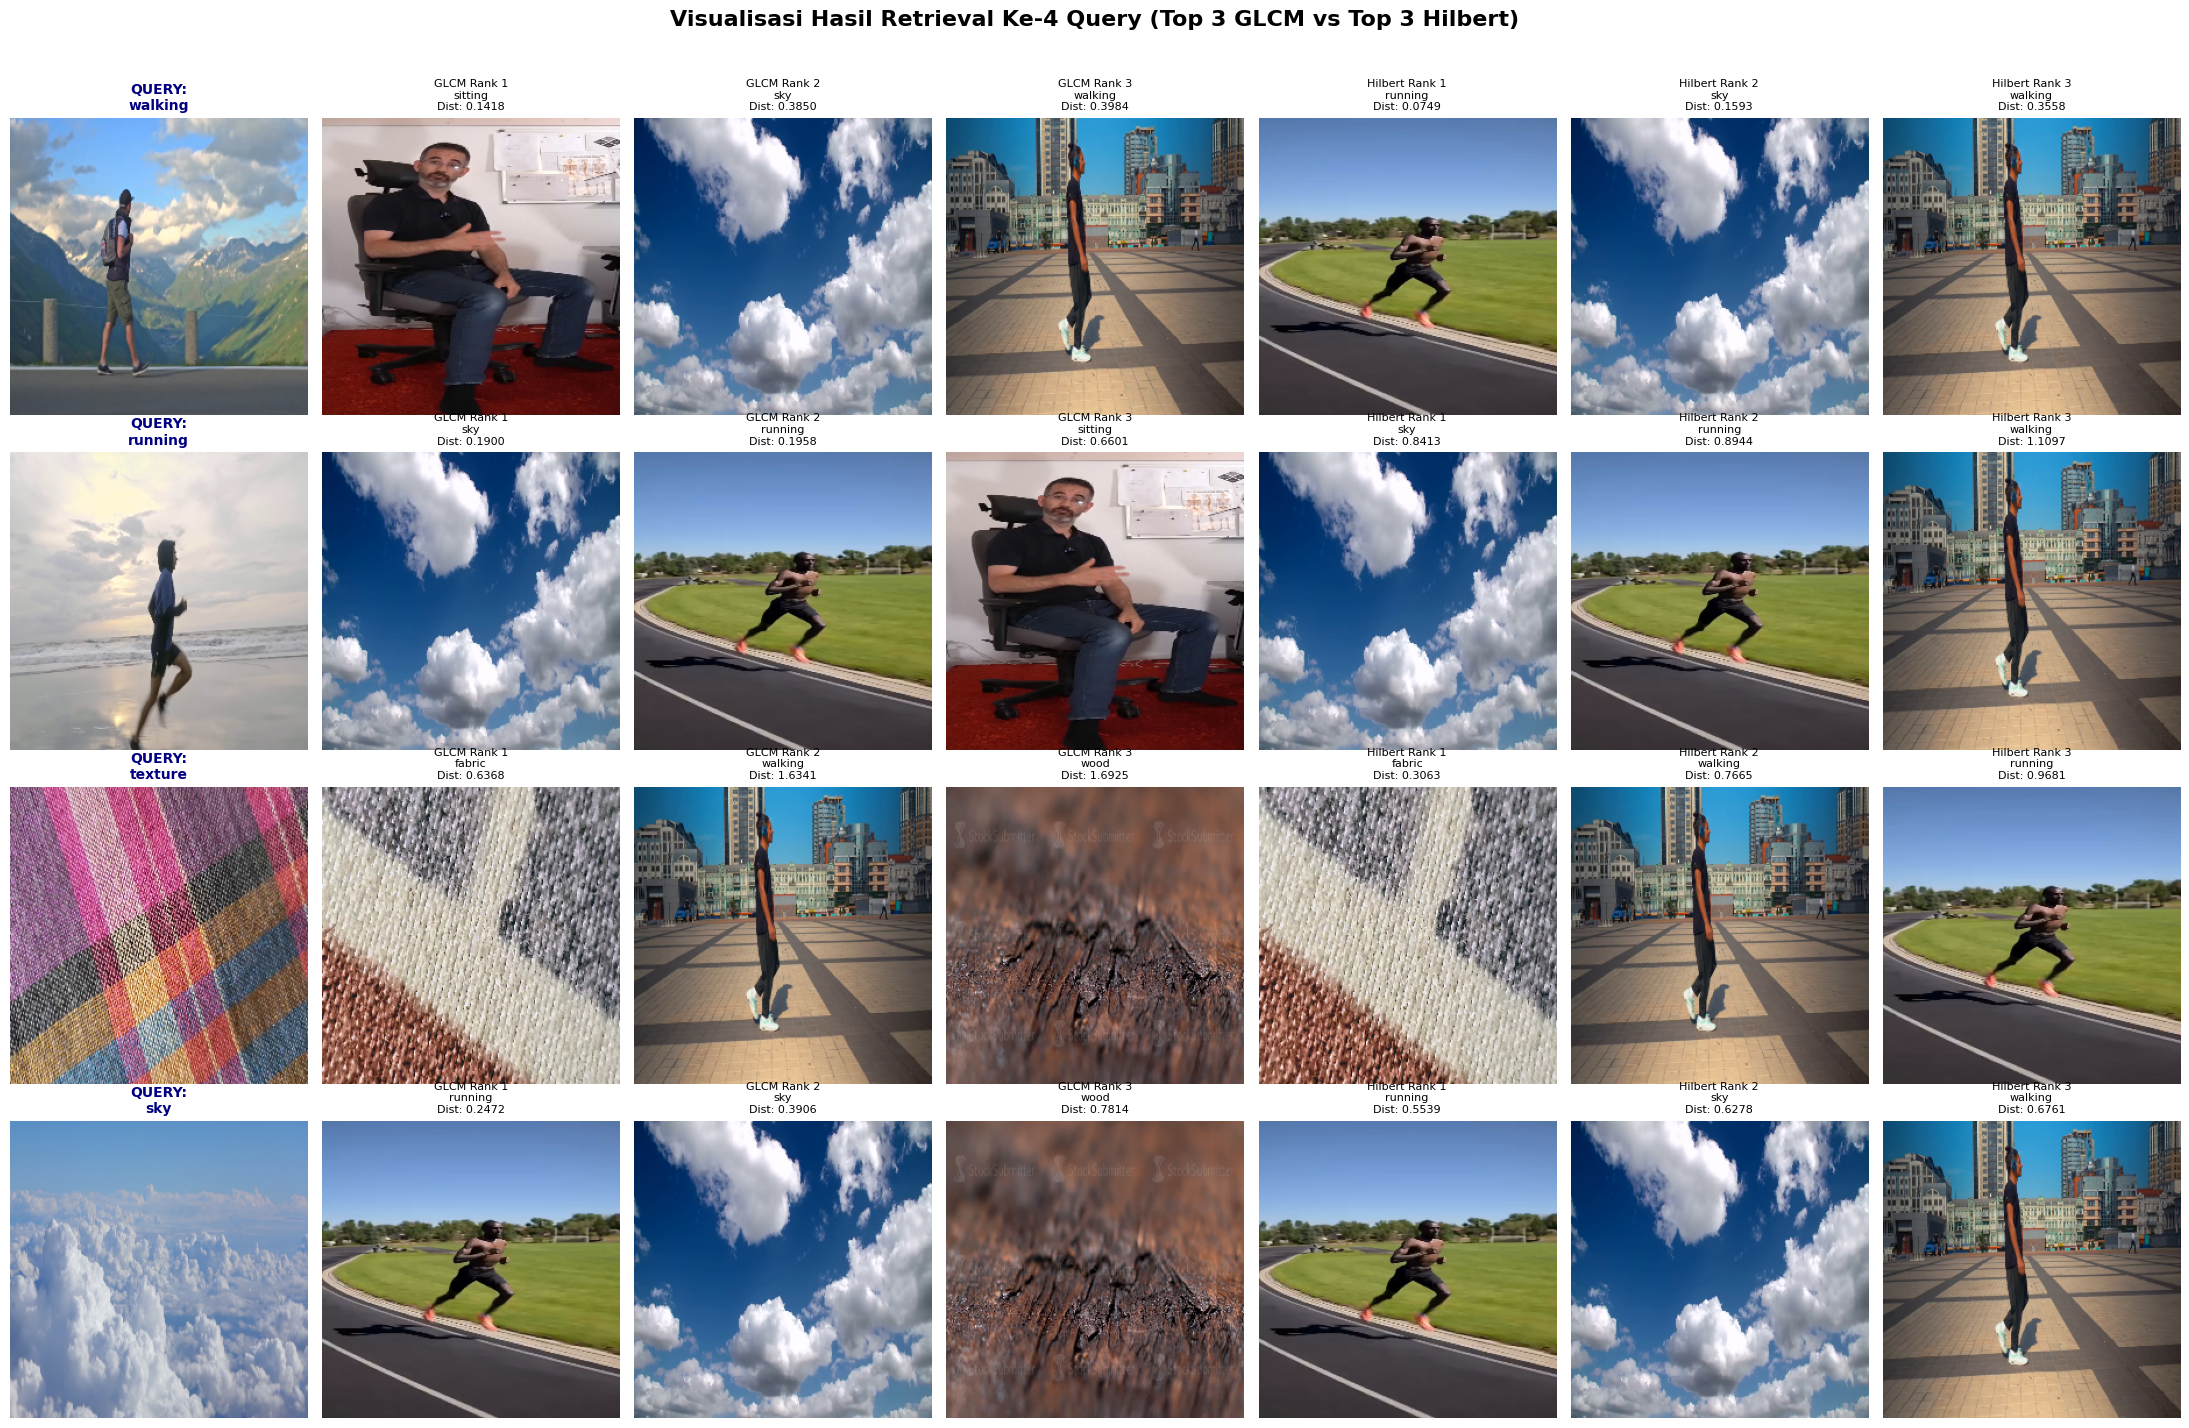

In [ ]:
# ============================================================
# 5. Tampilkan DataFrame Top 3 per Query dan Metode
# ============================================================
for q_name in QUERY_PATHS.keys():
    print("=" * 60)
    print(f"HASIL PENCARIAN (TOP 3) UNTUK: {q_name.upper()}")
    print("=" * 60)

    df_g = results[q_name]["GLCM"]
    df_h = results[q_name]["Hilbert"]

    print("&gt;&gt;&gt; Berdasarkan Fitur GLCM (Top 3):")
    display(df_g.head(3))

    print("\n&gt;&gt;&gt; Berdasarkan Fitur Hilbert (Top 3):")
    display(df_h.head(3))
    print("\n")

# ============================================================
# 6. Visualisasi Grid (4 Baris x 7 Kolom)
# - Baris 1-4 : Query 1 s/d Query 4
# - Kolom 1   : Gambar Query
# - Kolom 2-4 : Top 3 Match GLCM
# - Kolom 5-7 : Top 3 Match Hilbert
# ============================================================
fig, axes = plt.subplots(4, 7, figsize=(22, 14))

for row_idx, (q_name, q_img) in enumerate(query_images.items()):
    df_g = results[q_name]["GLCM"]
    df_h = results[q_name]["Hilbert"]

    # --- Kolom 0: Gambar Query ---
    axes[row_idx, 0].imshow(q_img)
    axes[row_idx, 0].set_title(f"QUERY:\n{q_name}", fontsize=10, fontweight='bold', color='navy')
    axes[row_idx, 0].axis("off")

    # --- Kolom 1-3: Top 3 Best Match GLCM ---
    for i in range(3):
        col_idx = 1 + i
        if i < len(df_g):
            match_vid = df_g.iloc[i]["Video"]
            match_dist = df_g.iloc[i]["Distance"]
            axes[row_idx, col_idx].imshow(video_keyframes_preview[match_vid])
            axes[row_idx, col_idx].set_title(f"GLCM Rank {i+1}\n{match_vid}\nDist: {match_dist:.4f}", fontsize=8)
        axes[row_idx, col_idx].axis("off")

    # --- Kolom 4-6: Top 3 Best Match Hilbert ---
    for i in range(3):
        col_idx = 4 + i
        if i < len(df_h):
            match_vid = df_h.iloc[i]["Video"]
            match_dist = df_h.iloc[i]["Distance"]
            axes[row_idx, col_idx].imshow(video_keyframes_preview[match_vid])
            axes[row_idx, col_idx].set_title(f"Hilbert Rank {i+1}\n{match_vid}\nDist: {match_dist:.4f}", fontsize=8)
        axes[row_idx, col_idx].axis("off")

plt.suptitle("Visualisasi Hasil Retrieval Ke-4 Query (Top 3 GLCM vs Top 3 Hilbert)", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()